In [1]:
!pip install skorch -q

import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 9.7 MB/s eta 0:00:00
cuda


In [2]:
#vérification du chemin des fichiers
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv


In [3]:
path = glob.glob("/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv", recursive=True)[0]
print(path)
df = pd.read_csv(path)
print(df.shape)
df.info()
df.head()

/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv
(10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [4]:
print(df.isnull().sum())
print("Lignes dupliquées :", df.duplicated().sum())
print("Product ID dupliqués :", df["Product ID"].duplicated().sum())
print(df["Failure Type"].value_counts())
print(pd.crosstab(df["Target"], df["Failure Type"]))

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64
Lignes dupliquées : 0
Product ID dupliqués : 0
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64
Failure Type  Heat Dissipation Failure  No Failure  Overstrain Failure  \
Target                                                                   
0                                    0        9643                   0   
1                                  112           9                  78   

Failure Type  Power Failure  Random Failures  Tool Wear Failure  
Target                                            

In [5]:
# 1. Renommons les colonnes (plus simples à manipuler)
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rot_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
})

# 2. Supprimer les lignes aux étiquettes contradictoires (panne signalée mais type "No Failure")
mask = (df["Target"] == 1) & (df["Failure Type"] == "No Failure")
print("Lignes incohérentes supprimées :", mask.sum())
df = df[~mask].reset_index(drop=True)

# 3. Supprimer les colonnes inutiles ou dangereuses
#    UDI, Product ID : simples identifiants
#    Target : dérivée de Failure Type, la garder serait une fuite de données (data leakage)
df = df.drop(columns=["UDI", "Product ID", "Target"])

# 4. Encoder Type (qualité du produit : L < M < H)
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# 5. Encoder la cible multi-classes
le = LabelEncoder()
df["label"] = le.fit_transform(df["Failure Type"])
print(dict(zip(le.classes_, le.transform(le.classes_))))
df.head()

Lignes incohérentes supprimées : 9
{'Heat Dissipation Failure': np.int64(0), 'No Failure': np.int64(1), 'Overstrain Failure': np.int64(2), 'Power Failure': np.int64(3), 'Random Failures': np.int64(4), 'Tool Wear Failure': np.int64(5)}


,Type,air_temp,process_temp,rot_speed,torque,tool_wear,Failure Type,label
0,1,298.1,308.6,1551,42.8,0,No Failure,1
1,0,298.2,308.7,1408,46.3,3,No Failure,1
2,0,298.1,308.5,1498,49.4,5,No Failure,1
3,0,298.2,308.6,1433,39.5,7,No Failure,1
4,0,298.2,308.7,1408,40.0,9,No Failure,1


In [6]:
features = ["Type", "air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]
X, y = df[features], df["label"]

# Split STRATIFIÉ : chaque classe garde sa proportion dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Standardisation : on apprend (fit) sur le train uniquement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train_s.shape, X_test_s.shape)
print(y_train.value_counts().sort_index())

(7992, 6) (1999, 6)
label
0      90
1    7714
2      62
3      76
4      14
5      36
Name: count, dtype: int64


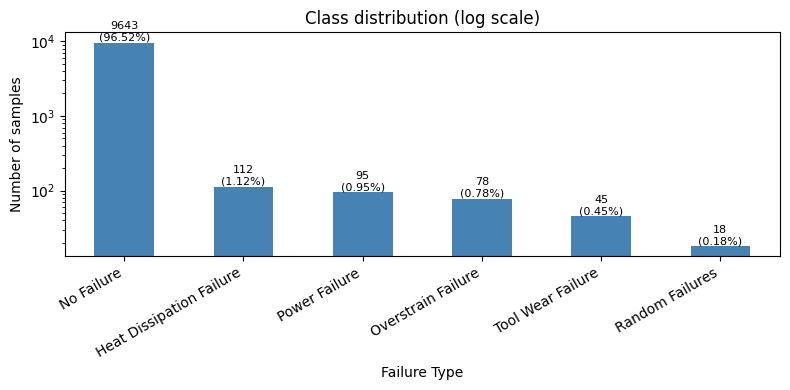

In [7]:
num_cols = ["air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]

counts = df["Failure Type"].value_counts()
ax = counts.plot(kind="bar", figsize=(8, 4), color="steelblue")
ax.set_yscale("log")
ax.set_title("Class distribution (log scale)")
ax.set_ylabel("Number of samples")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({v/len(df):.2%})", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("p2_class_distribution.png", dpi=150)
plt.show()

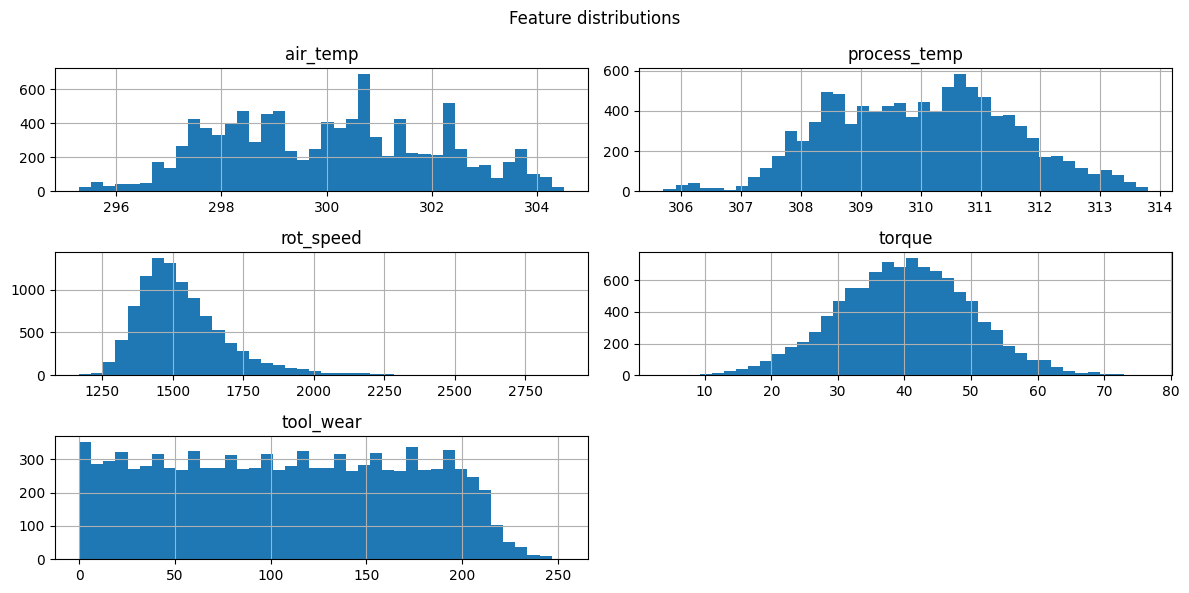

       air_temp  process_temp  rot_speed   torque  tool_wear
count    9991.0       9991.00    9991.00  9991.00    9991.00
mean      300.0        310.01    1538.80    39.99     107.94
std         2.0          1.48     179.32     9.97      63.66
min       295.3        305.70    1168.00     3.80       0.00
25%       298.3        308.80    1423.00    33.20      53.00
50%       300.1        310.10    1503.00    40.10     108.00
75%       301.5        311.10    1612.00    46.70     162.00
max       304.5        313.80    2886.00    76.60     253.00


In [8]:
df[num_cols].hist(bins=40, figsize=(12, 6))
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.savefig("p2_feature_distributions.png", dpi=150)
plt.show()

print(df[num_cols].describe().round(2))

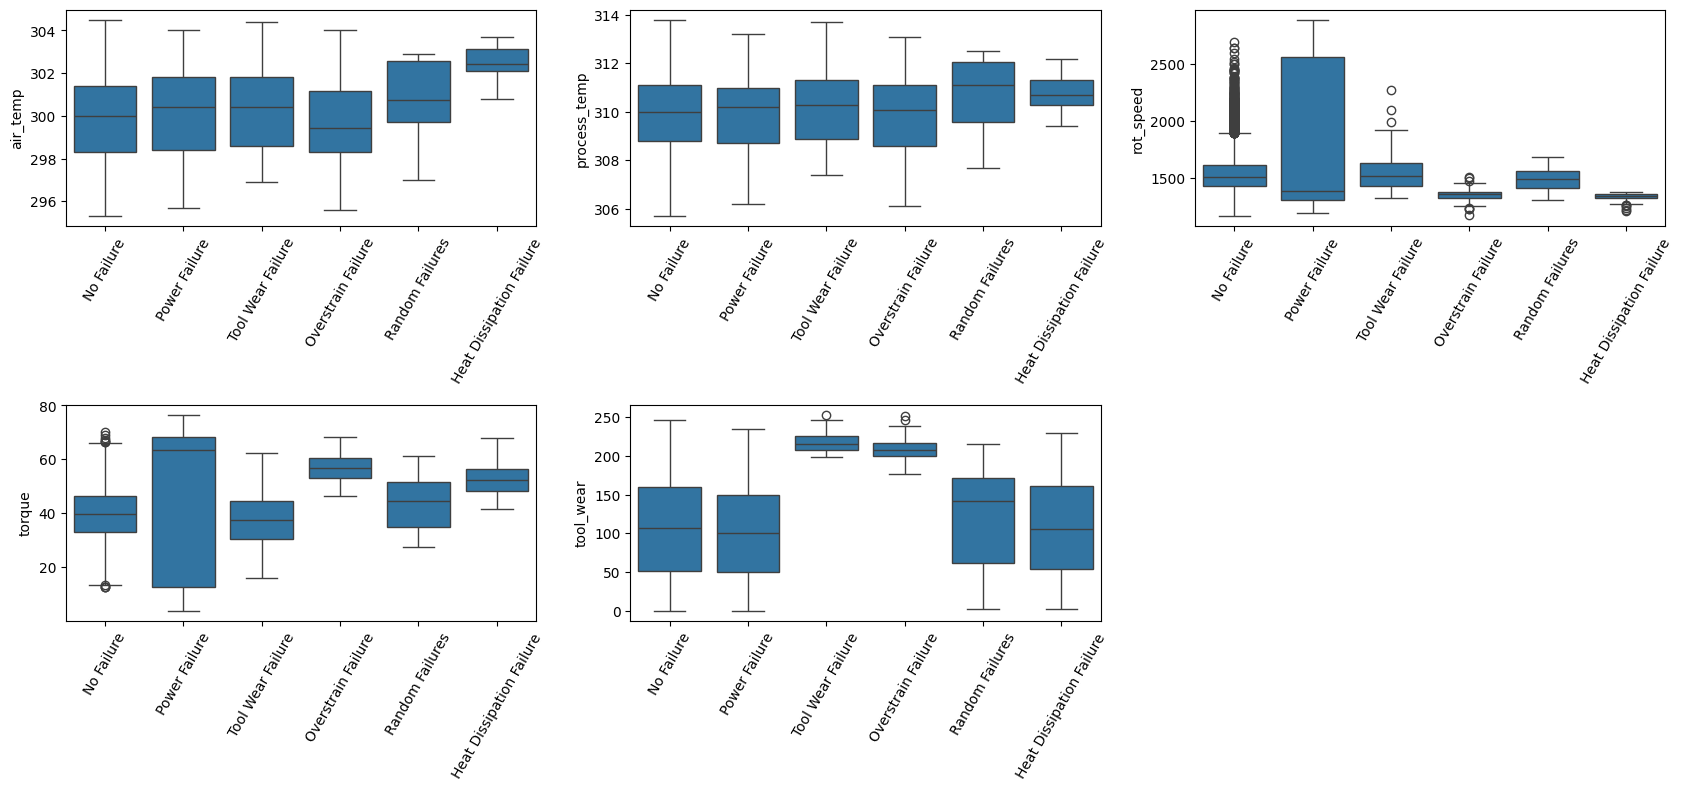

                          air_temp  process_temp  rot_speed  torque  tool_wear
Failure Type                                                                  
Heat Dissipation Failure     302.6         310.8     1338.0    52.8      107.3
No Failure                   300.0         310.0     1540.4    39.6      106.7
Overstrain Failure           299.9         310.1     1354.2    56.9      208.2
Power Failure                300.1         310.0     1764.0    48.5      101.9
Random Failures              300.8         310.8     1489.4    43.5      119.9
Tool Wear Failure            300.3         310.2     1570.7    37.2      216.6


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Failure Type", y=col, ax=ax)
    ax.tick_params(axis="x", rotation=60)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("p2_boxplots_by_failure.png", dpi=150)
plt.show()

print(df.groupby("Failure Type")[num_cols].mean().round(1))

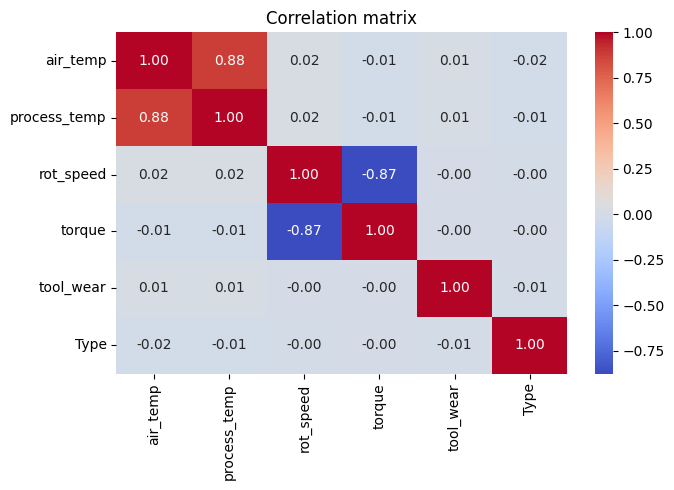

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["Type"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("p2_correlation.png", dpi=150)
plt.show()

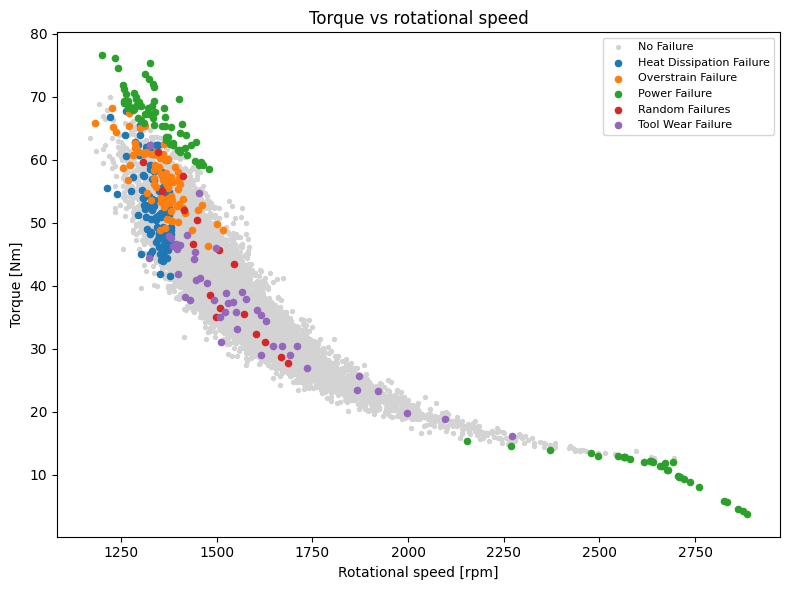

Failure Type  Heat Dissipation Failure  No Failure  Overstrain Failure  \
Type                                                                     
0                                0.012       0.959               0.012   
1                                0.010       0.973               0.001   
2                                0.008       0.976               0.001   

Failure Type  Power Failure  Random Failures  Tool Wear Failure  
Type                                                             
0                     0.010            0.002              0.004  
1                     0.010            0.001              0.005  
2                     0.005            0.004              0.006  


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
nf = df[df["Failure Type"] == "No Failure"]
ax.scatter(nf["rot_speed"], nf["torque"], c="lightgrey", s=8, label="No Failure")
for ft, g in df[df["Failure Type"] != "No Failure"].groupby("Failure Type"):
    ax.scatter(g["rot_speed"], g["torque"], s=20, label=ft)
ax.set_xlabel("Rotational speed [rpm]"); ax.set_ylabel("Torque [Nm]")
ax.set_title("Torque vs rotational speed")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("p2_torque_vs_speed.png", dpi=150)
plt.show()

print(pd.crosstab(df["Type"], df["Failure Type"], normalize="index").round(3))

In [12]:
from collections import Counter
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler

print("Avant :", sorted(Counter(y_train).items()))

# 1. Sous-échantillonner la classe majoritaire (label 1 = No Failure)
rus = RandomUnderSampler(sampling_strategy={1: 2000}, random_state=42)
X_tmp, y_tmp = rus.fit_resample(X_train, y_train)

# 2. SMOTENC : classes minoritaires (0, 2, 3, 4, 5) jusqu'à 2000 exemples
#    Type (colonne 0) est traitée comme variable catégorielle
target = {c: 2000 for c in [0, 2, 3, 4, 5]}
smote = SMOTENC(categorical_features=[0], sampling_strategy=target,
                k_neighbors=5, random_state=42)
X_res, y_res = smote.fit_resample(X_tmp, y_tmp)

print("Après :", sorted(Counter(y_res).items()))
print("Valeurs de Type :", sorted(X_res["Type"].unique()))   # doit rester 0, 1, 2

# Standardisation avec le scaler de la Q1 (appris sur le train d'origine)
X_res_s = scaler.transform(X_res)
print(X_res_s.shape, X_test_s.shape)

Avant : [(0, 90), (1, 7714), (2, 62), (3, 76), (4, 14), (5, 36)]
Après : [(0, 2000), (1, 2000), (2, 2000), (3, 2000), (4, 2000), (5, 2000)]
Valeurs de Type : [np.int64(0), np.int64(1), np.int64(2)]
(12000, 6) (1999, 6)


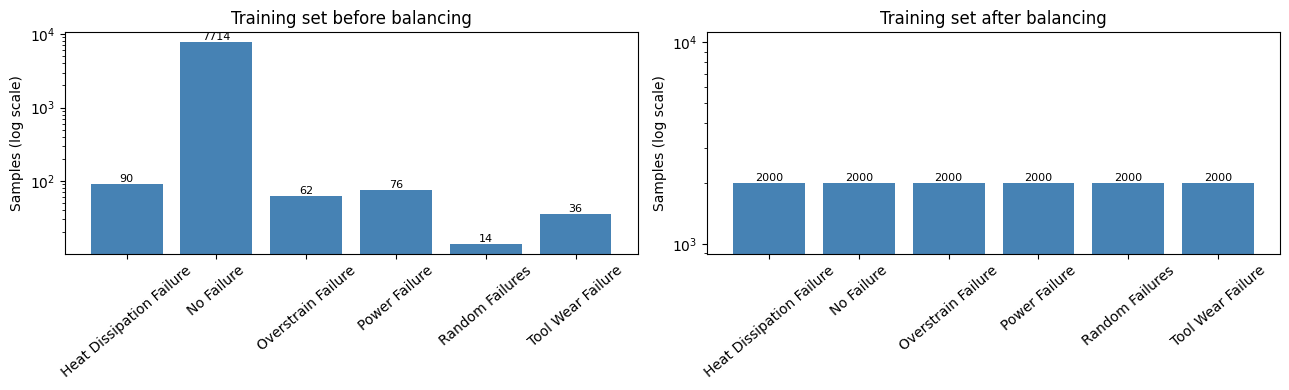

In [13]:
names = le.classes_
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, yy, title in zip(ax, [y_train, y_res], ["Training set before balancing", "Training set after balancing"]):
    c = pd.Series(yy).value_counts().sort_index()
    a.bar([names[i] for i in c.index], c.values, color="steelblue")
    a.set_yscale("log")
    a.set_title(title); a.set_ylabel("Samples (log scale)")
    a.tick_params(axis="x", rotation=40)
    for i, v in enumerate(c.values):
        a.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig("p2_balancing.png", dpi=150)
plt.show()

In [14]:
# Tenseurs : train équilibré, test réel
Xtr_t = torch.tensor(X_res_s, dtype=torch.float32)
ytr_t = torch.tensor(np.asarray(y_res), dtype=torch.long)
Xte_t = torch.tensor(X_test_s, dtype=torch.float32)
yte_t = torch.tensor(np.asarray(y_test), dtype=torch.long)

train_dl = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=256, shuffle=True)
test_dl  = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=512)

class ClfMLP(nn.Module):
    def __init__(self, in_dim=6, n_classes=6, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))   # logits (softmax intégré dans CrossEntropyLoss)
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def evaluate_clf(model, loader, criterion):
    model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            tot_loss += criterion(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

def train_clf(model, epochs=30, lr=1e-3, opt_cls=torch.optim.Adam, weight_decay=0.0, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        trl, tra = evaluate_clf(model, train_dl, criterion)
        tel, tea = evaluate_clf(model, test_dl, criterion)
        h["train_loss"].append(trl); h["test_loss"].append(tel)
        h["train_acc"].append(tra);  h["test_acc"].append(tea)
        if verbose and (epoch == 0 or (epoch + 1) % 5 == 0):
            print(f"Epoch {epoch+1:02d} | loss {trl:.4f}/{tel:.4f} | acc {tra:.4f}/{tea:.4f}")
    return h

torch.manual_seed(0)
clf_base = ClfMLP().to(device)
print(clf_base)
history_clf_base = train_clf(clf_base, epochs=30, lr=1e-3)

ClfMLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)
Epoch 01 | loss 1.3520/1.5318 | acc 0.6027/0.3087
Epoch 05 | loss 0.3514/0.8183 | acc 0.8888/0.6288
Epoch 10 | loss 0.2359/0.6669 | acc 0.9248/0.6998
Epoch 15 | loss 0.1915/0.5453 | acc 0.9407/0.7629
Epoch 20 | loss 0.1650/0.5794 | acc 0.9517/0.7544
Epoch 25 | loss 0.1441/0.4793 | acc 0.9624/0.8014
Epoch 30 | loss 0.1311/0.4957 | acc 0.9633/0.8014


In [15]:
from sklearn.model_selection import PredefinedSplit, GridSearchCV
from skorch import NeuralNetClassifier

# 1. Split du train ORIGINAL (réel, non équilibré) : fit / validation
Xf, Xv, yf, yv = train_test_split(X_train, y_train, test_size=0.2,
                                  stratify=y_train, random_state=0)

# 2. Équilibrer uniquement la partie fit (même méthode que Q3)
Xf2, yf2 = RandomUnderSampler(sampling_strategy={1: 2000}, random_state=0).fit_resample(Xf, yf)
Xf3, yf3 = SMOTENC(categorical_features=[0],
                   sampling_strategy={c: 2000 for c in [0, 2, 3, 4, 5]},
                   k_neighbors=5, random_state=0).fit_resample(Xf2, yf2)

# 3. Données combinées + découpage fixe (-1 = toujours en entraînement, 0 = validation)
X_gs = np.vstack([scaler.transform(Xf3), scaler.transform(Xv)]).astype(np.float32)
y_gs = np.concatenate([np.asarray(yf3), np.asarray(yv)]).astype(np.int64)
test_fold = np.r_[-np.ones(len(Xf3)), np.zeros(len(Xv))].astype(int)
ps = PredefinedSplit(test_fold)

# 4. Modèle skorch
class MLPClf(nn.Module):
    def __init__(self, n_hidden=64, n_layers=2, in_dim=6, n_classes=6):
        super().__init__()
        layers, prev = [], in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(prev, n_hidden), nn.ReLU()]
            prev = n_hidden
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

net = NeuralNetClassifier(
    MLPClf, criterion=nn.CrossEntropyLoss, optimizer=torch.optim.Adam,
    max_epochs=20, lr=1e-3, batch_size=256,
    device=device, verbose=0, train_split=None
)

param_grid = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__n_hidden": [32, 64],
    "module__n_layers": [1, 2],
}

grid = GridSearchCV(net, param_grid, cv=ps, scoring="f1_macro",
                    refit=False, n_jobs=1, verbose=1)
grid.fit(X_gs, y_gs)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur F1 macro (validation) :", round(grid.best_score_, 4))

cv = pd.DataFrame(grid.cv_results_)
cols = [c for c in cv.columns if c.startswith("param_")] + ["mean_test_score"]
cv[cols].sort_values("mean_test_score", ascending=False).head(5)

Fitting 1 folds for each of 32 candidates, totalling 32 fits
Meilleurs paramètres : {'lr': 0.01, 'max_epochs': 40, 'module__n_hidden': 64, 'module__n_layers': 1, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur F1 macro (validation) : 0.3451


,param_lr,param_max_epochs,param_module__n_hidden,param_module__n_layers,param_optimizer,mean_test_score
12,0.010,40,64,1,<class 'torch.optim.adam.Adam'>,0.345078
30,0.001,40,64,2,<class 'torch.optim.adam.Adam'>,0.335909
10,0.010,40,32,2,<class 'torch.optim.adam.Adam'>,0.330929
8,0.010,40,32,1,<class 'torch.optim.adam.Adam'>,0.329520
4,0.010,20,64,1,<class 'torch.optim.adam.Adam'>,0.316494


In [16]:
bp = grid.best_params_
torch.manual_seed(0)
clf_best = ClfMLP(hidden=(bp["module__n_hidden"],) * bp["module__n_layers"]).to(device)
history_clf_best = train_clf(clf_best, epochs=bp["max_epochs"], lr=bp["lr"], opt_cls=bp["optimizer"])

Epoch 01 | loss 0.4037/0.9036 | acc 0.8531/0.6063
Epoch 05 | loss 0.1861/0.5964 | acc 0.9429/0.7319
Epoch 10 | loss 0.1391/0.5157 | acc 0.9579/0.7974
Epoch 15 | loss 0.1110/0.4760 | acc 0.9672/0.8304
Epoch 20 | loss 0.0943/0.4432 | acc 0.9733/0.8419
Epoch 25 | loss 0.0895/0.4953 | acc 0.9745/0.8424
Epoch 30 | loss 0.0811/0.3417 | acc 0.9817/0.8889
Epoch 35 | loss 0.0748/0.3439 | acc 0.9834/0.8969
Epoch 40 | loss 0.0671/0.4054 | acc 0.9822/0.8834


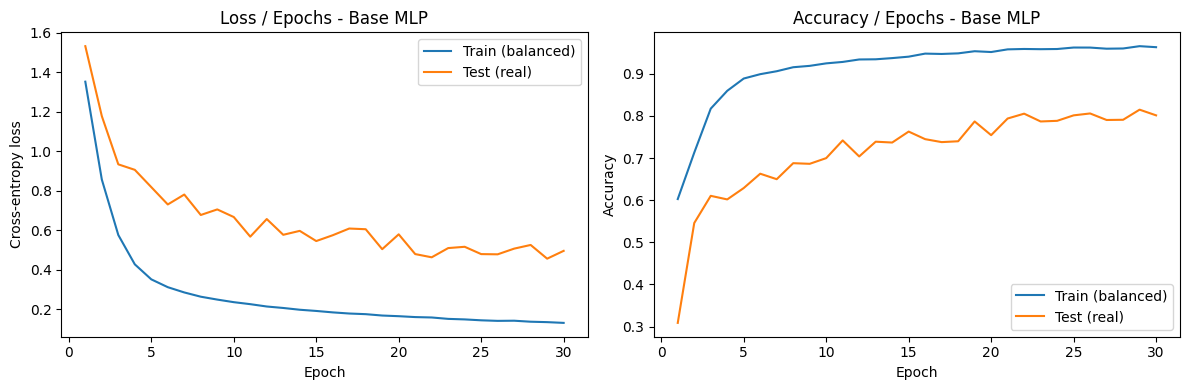

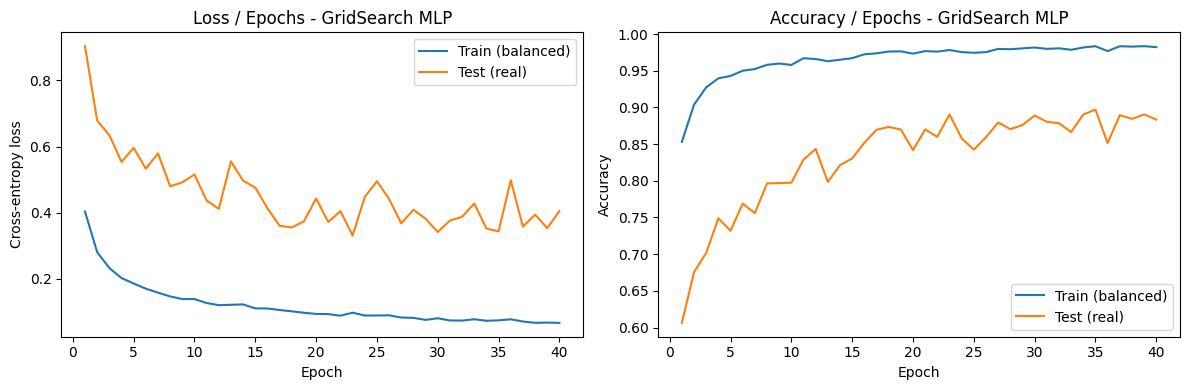

In [17]:
def plot_clf_history(h, title, fname):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h["train_loss"], label="Train (balanced)")
    ax[0].plot(ep, h["test_loss"], label="Test (real)")
    ax[0].set_title(f"Loss / Epochs - {title}")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="Train (balanced)")
    ax[1].plot(ep, h["test_acc"], label="Test (real)")
    ax[1].set_title(f"Accuracy / Epochs - {title}")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

plot_clf_history(history_clf_base, "Base MLP", "p2_curves_base.png")
plot_clf_history(history_clf_best, "GridSearch MLP", "p2_curves_best.png")

In [18]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

def predict(model, X):
    model.eval()
    with torch.no_grad():
        xt = torch.tensor(np.asarray(X), dtype=torch.float32).to(device)
        return model(xt).argmax(1).cpu().numpy()

sets = {
    "Train (balanced)":          (X_res_s,   np.asarray(y_res)),
    "Train (real distribution)": (X_train_s, np.asarray(y_train)),
    "Test (real distribution)":  (X_test_s,  np.asarray(y_test)),
}

def summary(model):
    rows = []
    for name, (X, y) in sets.items():
        p = predict(model, X)
        pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
        f1w = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)[2]
        rows.append({"Set": name, "Accuracy": accuracy_score(y, p),
                     "Precision (macro)": pr, "Sensitivity (macro recall)": rc,
                     "F1 (macro)": f1, "F1 (weighted)": f1w})
    return pd.DataFrame(rows).set_index("Set")

table = pd.concat({"Base MLP": summary(clf_base), "GridSearch MLP": summary(clf_best)})
table.round(4)

Accuracy  Precision (macro)  \
               Set                                                      
Base MLP       Train (balanced)             0.9632             0.9651   
               Train (real distribution)    0.8197             0.4077   
               Test (real distribution)     0.8014             0.3941   
GridSearch MLP Train (balanced)             0.9822             0.9826   
               Train (real distribution)    0.8946             0.4484   
               Test (real distribution)     0.8834             0.4073   

                                          Sensitivity (macro recall)  \
               Set                                                     
Base MLP       Train (balanced)                               0.9632   
               Train (real distribution)                      0.9054   
               Test (real distribution)                       0.6813   
GridSearch MLP Train (balanced)                               0.9822   
               Train (real distribution)                      0.9284   
               Test (real distribution)                       0.6487   

                                          F1 (macro)  F1 (weighted)  
               Set                                                   
Base MLP       Train (balanced)               0.9623         0.9623  
               Train (real distribution)      0.4855         0.8844  
               Test (real distribution)       0.4625         0.8730  
GridSearch MLP Train (balanced)               0.9819         0.9819  
               Train (real distribution)      0.5377         0.9301  
               Test (real distribution)       0.4797         0.9224

                          precision    recall  f1-score   support

Heat Dissipation Failure      0.458     1.000     0.629        22
              No Failure      0.994     0.886     0.937      1929
      Overstrain Failure      0.533     1.000     0.696        16
           Power Failure      0.447     0.895     0.596        19
         Random Failures      0.000     0.000     0.000         4
       Tool Wear Failure      0.011     0.111     0.021         9

                accuracy                          0.883      1999
               macro avg      0.407     0.649     0.480      1999
            weighted avg      0.972     0.883     0.922      1999



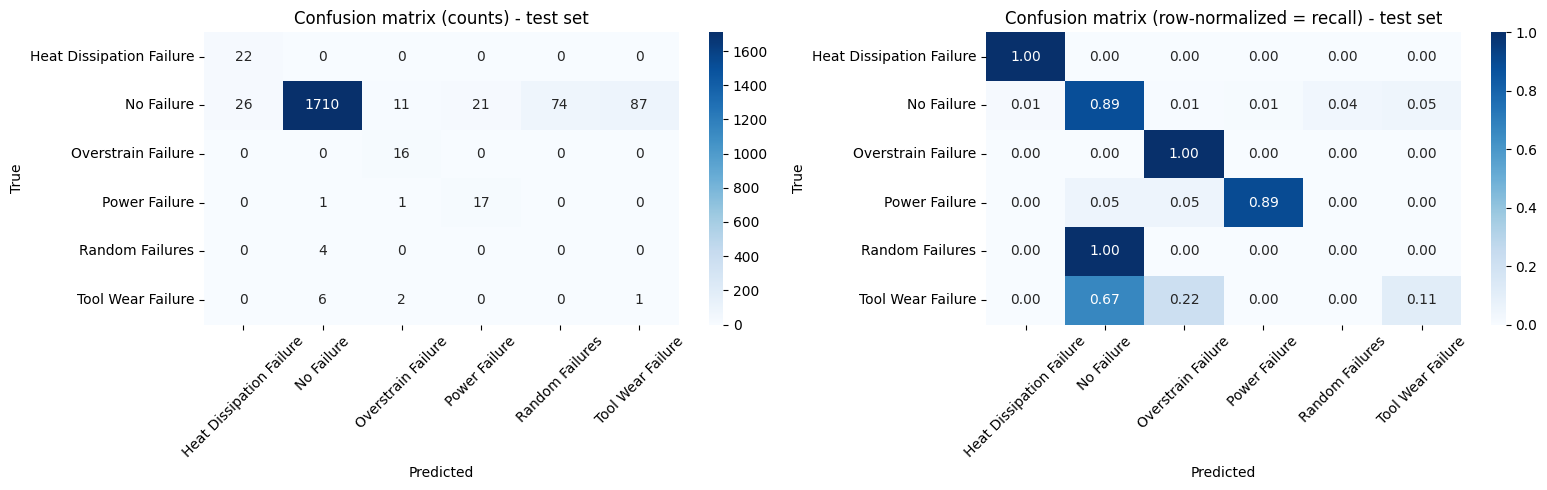

In [19]:
labels = list(range(6))
y_pred_te = predict(clf_best, X_test_s)
print(classification_report(y_test, y_pred_te, labels=labels,
                            target_names=le.classes_, zero_division=0, digits=3))

cm = confusion_matrix(y_test, y_pred_te, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[0])
ax[0].set_title("Confusion matrix (counts) - test set")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalized = recall) - test set")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("p2_confusion_matrix.png", dpi=150); plt.show()

In [20]:
import copy, time

# Données : partie "fit" équilibrée / validation réelle / test réel (sans fuite)
Xf_s = scaler.transform(Xf3).astype(np.float32); yf_a = np.asarray(yf3)
Xv_s = scaler.transform(Xv).astype(np.float32);  yv_a = np.asarray(yv)
yte_a = np.asarray(y_test)
fit_dl = DataLoader(TensorDataset(torch.tensor(Xf_s), torch.tensor(yf_a, dtype=torch.long)),
                    batch_size=256, shuffle=True)

def macro(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return pr, rc, f1

def run_clf_experiment(name, model_kwargs=None, epochs=40, lr=1e-2, weight_decay=0.0, patience=None):
    torch.manual_seed(0)
    model = ClfMLP(hidden=(64,), **(model_kwargs or {})).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist, best_f1, best_state, best_epoch, wait = [], -1.0, None, 0, 0
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in fit_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        f1v = macro(yv_a, predict(model, Xv_s))[2]
        hist.append(f1v)
        if f1v > best_f1:
            best_f1, best_epoch, wait = f1v, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if patience and wait >= patience:
                break
    if patience:                       # early stopping : on restaure les meilleurs poids
        model.load_state_dict(best_state)
    p_tr, p_te = predict(model, Xf_s), predict(model, X_test_s)
    pr, rc, f1 = macro(yte_a, p_te)
    result = {
        "Model": name,
        "Train acc (balanced)": accuracy_score(yf_a, p_tr),
        "Train macro F1 (balanced)": macro(yf_a, p_tr)[2],
        "Best val macro F1": best_f1,
        "Test acc": accuracy_score(yte_a, p_te),
        "Test macro precision": pr, "Test macro recall": rc, "Test macro F1": f1,
        "Epochs run": len(hist), "Best epoch (val)": best_epoch,
        "Time (s)": round(time.time() - t0, 1),
    }
    return result, hist

configs = [
    ("1. Baseline",                              {},                   dict()),
    ("2. Weight decay (1e-3)",                   {},                   dict(weight_decay=1e-3)),
    ("3. Dropout (0.3)",                         dict(dropout=0.3),    dict()),
    ("4. BatchNorm",                             dict(batchnorm=True), dict()),
    ("5. Early stopping (patience 8)",           {},                   dict(patience=8)),
    ("6. Combined (Dropout 0.3 + WD 1e-4 + ES)", dict(dropout=0.3),    dict(weight_decay=1e-4, patience=8)),
]

results, hists = [], {}
for name, mk, kw in configs:
    print("Entraînement :", name)
    r, h = run_clf_experiment(name, mk, **kw)
    results.append(r); hists[name] = h

res_clf = pd.DataFrame(results).set_index("Model")
res_clf.round(4)

Entraînement : 1. Baseline
Entraînement : 2. Weight decay (1e-3)
Entraînement : 3. Dropout (0.3)
Entraînement : 4. BatchNorm
Entraînement : 5. Early stopping (patience 8)
Entraînement : 6. Combined (Dropout 0.3 + WD 1e-4 + ES)


,Train acc (balanced),Train macro F1 (balanced),Best val macro F1,Test acc,Test macro precision,Test macro recall,Test macro F1,Epochs run,Best epoch (val),Time (s)
Model,,,,,,,,,,
1. Baseline,0.9877,0.9875,0.5512,0.9135,0.4265,0.6278,0.4932,40,33,5.0
2. Weight decay (1e-3),0.9680,0.9670,0.4575,0.8249,0.3452,0.6484,0.4119,40,39,5.0
3. Dropout (0.3),0.9814,0.9811,0.5047,0.8924,0.4049,0.6687,0.4806,40,32,5.1
4. BatchNorm,0.9812,0.9810,0.5346,0.8934,0.4060,0.6146,0.4728,40,33,5.4
5. Early stopping (patience 8),0.9808,0.9805,0.5263,0.8969,0.4426,0.6250,0.5023,29,21,3.7
6. Combined (Dropout 0.3 + WD 1e-4 + ES),0.9760,0.9756,0.4689,0.8724,0.3886,0.6381,0.4589,31,23,3.9


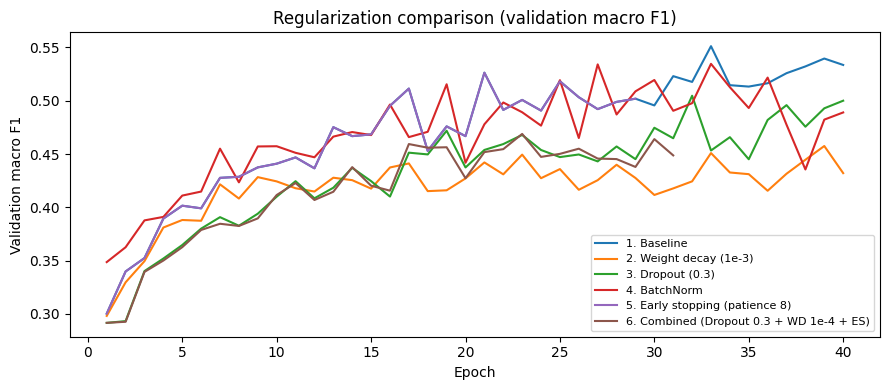

In [21]:
plt.figure(figsize=(9, 4))
for name, h in hists.items():
    plt.plot(range(1, len(h) + 1), h, label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation macro F1")
plt.title("Regularization comparison (validation macro F1)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("p2_regularization_comparison.png", dpi=150)
plt.show()